# Likelihood method example

Experiment with asymmetric measurement uncertainties

Author: Aleksander Filip Żarnecki (University of Warsaw)

### (0) Import libraries 

In [1]:
import math
import numpy as np
from scipy.stats import norm
from scipy.stats import uniform
import matplotlib.pyplot as plt

### (1) Probability distribution definition

In [2]:
# Nominal value

x0 = 20

# Left and right uncertainties

sig1 = 2
sig2 = 0.5

# Fraction of measurement below and above x0
# This is also used for normalisation (multiplied by 2)

f1 = sig1/(sig1+sig2)
f2 = 1 - f1

In [3]:
def mypdf(x,xmax=x0):
    
    p1 = norm.pdf(x,xmax,sig1)
    p2 = norm.pdf(x,xmax,sig2)

    is1 = ( x < xmax )

    p = is1 * 2 * f1 * p1  + (1-is1) * 2 * f2 * p2

    return p

In [4]:
def myisf(sf):

    is1 = ( sf > f2 )
    
    u1 = 1 - sf
    sf1 = 1.0 - np.minimum(0.5*u1/f1,1.0)
      
    sf2 = np.minimum(0.5*sf/f2,0.99999999) 
    
    i1 = norm.isf(sf1,x0,sig1)
    i2 = norm.isf(sf2,x0,sig2)

    isf = is1 * i1  + (1-is1) * i2

    return isf

In [5]:
def myrandom(N=1):

    rn = uniform.rvs(size=N)

    return myisf(rn)

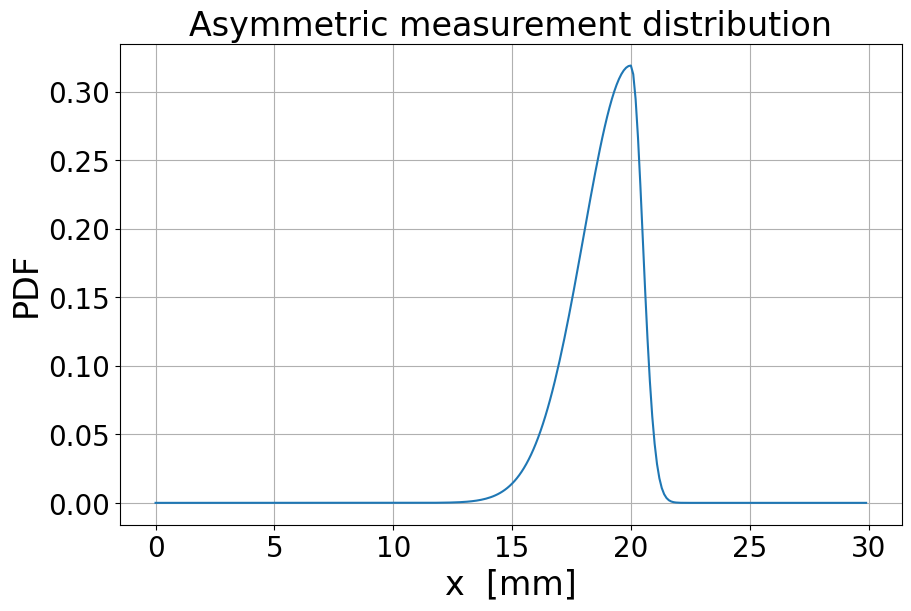

In [6]:
# Check distribution shape

x = np.arange(0.,30.,0.1)
y = mypdf(x)


plt.figure(figsize=(9, 6),layout='constrained')
plt.plot(x,y,'-')

plt.title("Asymmetric measurement distribution",size=24)
plt.xlabel('x  [mm]',size=24)
plt.ylabel('PDF',size=24)

plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(which='major', axis='both')

fname = '05_likelihood_pdf.png'
plt.savefig(fname)

plt.show()

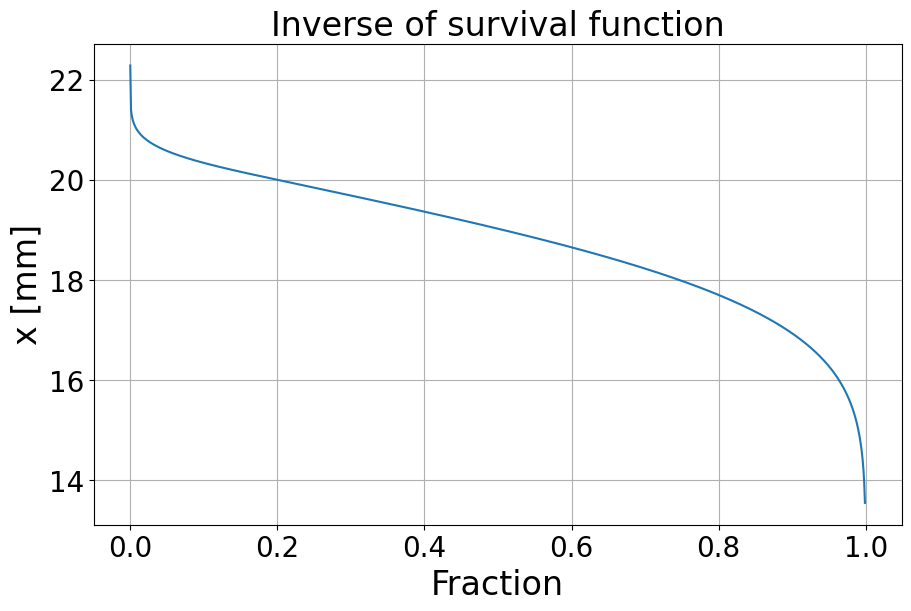

In [7]:
# Check inverse survival function

xs = np.arange(0.000001,0.999999,0.001)
ys = myisf(xs)

plt.figure(figsize=(9, 6),layout='constrained')
plt.plot(xs,ys,'-')

plt.title("Inverse of survival function",size=24)
plt.xlabel('Fraction',size=24)
plt.ylabel('x [mm]',size=24)

plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(which='major', axis='both')

fname = '05_likelihood_isf.png'
plt.savefig(fname)

plt.show()

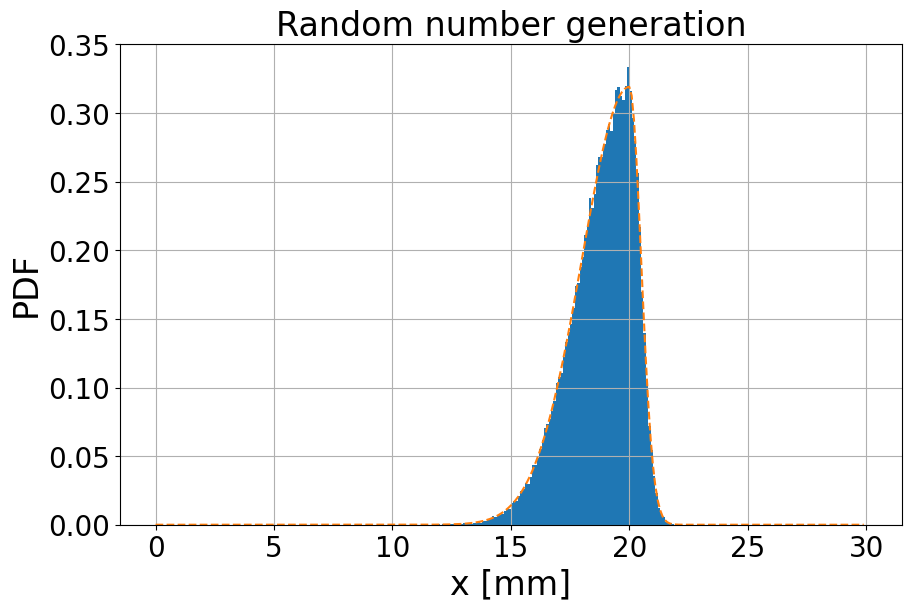

In [8]:
# Check random number generation

Ntest = 100000
xr = myrandom(Ntest)

plt.figure(figsize=(9, 6),layout='constrained')
plt.hist(xr,bins=300,range=(0.,30.),density=True)
plt.plot(x,y,'--')

plt.title("Random number generation",size=24)
plt.xlabel('x [mm]',size=24)
plt.ylabel('PDF',size=24)

plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(which='major', axis='both')

fname = '05_likelihood_random.png'
plt.savefig(fname)

plt.show()

### (2) Raw mean calculation

In [9]:
# 20 measurements in single experiment
# 1000 repeated experiments

Nmeas = 20
Nexp = 10000

xr = myrandom(Nmeas*Nexp).reshape((Nexp,Nmeas))

means = np.mean(xr,axis=1)


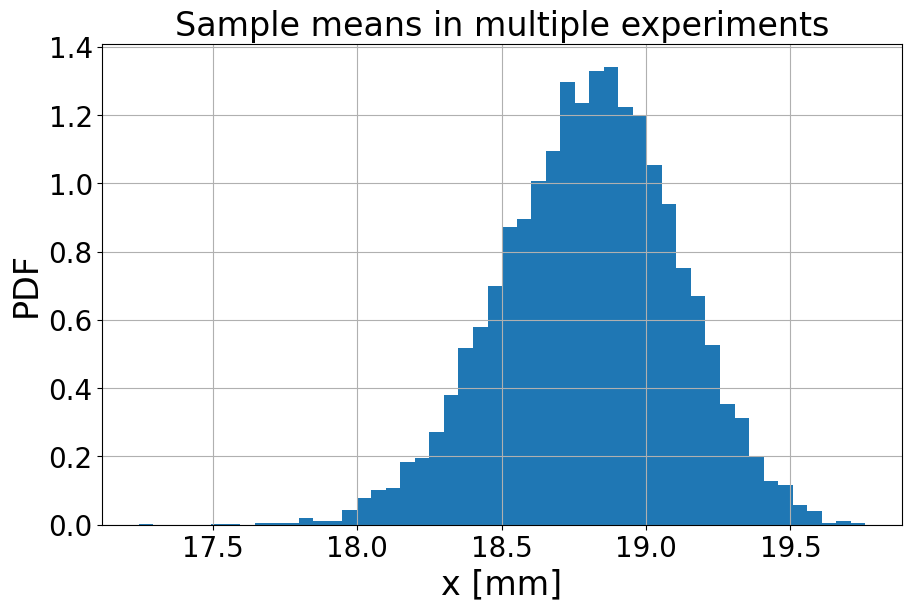

In [10]:
# Check random number generation

plt.figure(figsize=(9, 6),layout='constrained')
plt.hist(means,bins=50,density=True)

plt.title("Sample means in multiple experiments",size=24)
plt.xlabel('x [mm]',size=24)
plt.ylabel('PDF',size=24)

plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(which='major', axis='both')

fname = '05_likelihood_mean.png'
plt.savefig(fname)

plt.show()

### (3) Likelihood approach

In [11]:
def myll(x,xpar):
    return np.sum(np.log(mypdf(x,xpar)))

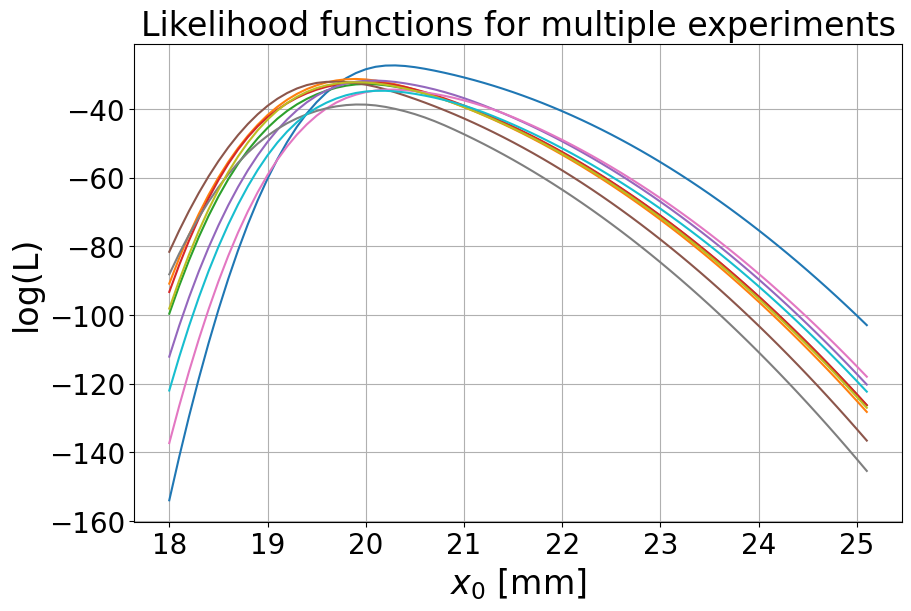

In [12]:
Nmeas = 20
Nexp = 10

# Likelihood function test range

xd = np.arange(18.0,25.1,0.1)
nx = xd.size

plt.figure(figsize=(9, 6),layout='constrained')

for iexp in range(Nexp):
    
    xl = myrandom(Nmeas)
    lld = np.zeros_like(xd)
    for ix in range(nx):
        lld[ix] = myll(xl,xd[ix])
        
    plt.plot(xd,lld)
    
plt.title("Likelihood functions for multiple experiments",size=24)
plt.xlabel('$x_{0}$ [mm]',size=24)
plt.ylabel('log(L)',size=24)

plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(which='major', axis='both')

fname = '05_likelihood_ll.png'
plt.savefig(fname)

plt.show()

In [13]:
Nmeas = 20
Nexp = 10000

# Likelihood function test range

xd = np.arange(19.005,21.005,0.01)
nx = xd.size

xll = np.zeros(Nexp)
xl = myrandom(Nmeas*Nexp).reshape((Nexp,Nmeas))

for iexp in range(Nexp):
    
    lld = np.zeros_like(xd)
    for ix in range(nx):
        lld[ix] = myll(xl[iexp,:],xd[ix])
        
    imax = np.argmax(lld)
    xll[iexp]=xd[imax]

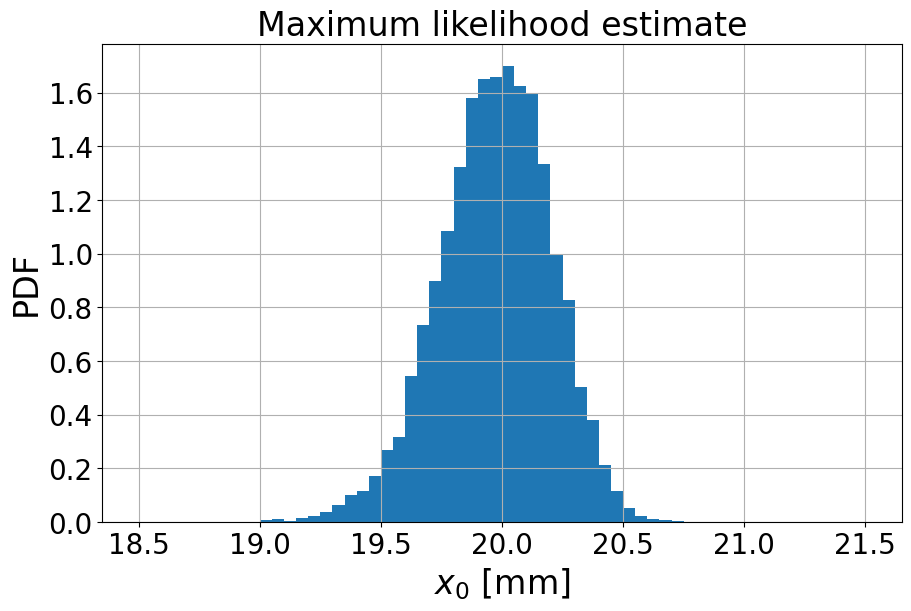

In [14]:
plt.figure(figsize=(9, 6),layout='constrained')
plt.hist(xll,bins=60,range=(18.5,21.5),density=True)
    
plt.title("Maximum likelihood estimate",size=24)
plt.xlabel('$x_{0}$ [mm]',size=24)
plt.ylabel('PDF',size=24)

plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(which='major', axis='both')

fname = '05_likelihood_ll2.png'
plt.savefig(fname)

plt.show()